## Analyze A/B Test Results


## Table of Contents
- [Introduction](#intro)
- [Part I - Probability](#probability)
- [Part II - A/B Test](#ab_test)
- [Part III - Regression](#regression)


<a id='intro'></a>
### Introduction

A/B tests are very commonly performed by data analysts and data scientists.  It is important that you get some practice working with the difficulties of these 

For this project, We will be working to understand the results of an A/B test run by an e-commerce website.  We goal is to work through this notebook to help the company understand if they should implement the new page, keep the old page, or perhaps run the experiment longer to make their decision.


<a id='probability'></a>
#### Part I - Probability


In [1]:
#import libraries.
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score
from sklearn.model_selection import train_test_split
import statsmodels.api as sm

#We are setting the seed to assure you get the same answers on quizzes as we set up
random.seed(42)

/opt/conda/lib/python3.6/site-packages/statsmodels/compat/pandas.py:56: FutureWarning: The pandas.core.datetools module is deprecated and will be removed in a future version. Please use the pandas.tseries module instead.
  from pandas.core import datetools



Read in the dataset and take a look at the top few rows here:

In [2]:
df=pd.read_csv('ab_data.csv')
df.head()

,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


Find the number of rows in the dataset.

In [3]:
df.shape

(294478, 5)

The number of unique users in the dataset.

In [4]:
unique_users= df['user_id'].unique()
len(unique_users)


290584

In [5]:
num_user_dup= df[df['user_id'].duplicated()].count()
num_user_dup

user_id         3894
timestamp       3894
group           3894
landing_page    3894
converted       3894
dtype: int64

The proportion of users converted.

In [6]:
df['converted'].mean()


0.11965919355605512

The number of times the `new_page` and `treatment` don't match.

In [7]:
df.query('(landing_page == "new_page" and group !="treatment") or (landing_page != "new_page" and group =="treatment")')['user_id'].count()



3893

The number of missing values?

In [8]:
df.isnull().sum()

user_id         0
timestamp       0
group           0
landing_page    0
converted       0
dtype: int64

For the rows where **treatment** does not match with **new_page** or **control** does not match with **old_page**, we cannot be sure if this row truly received the new or old page. We create a new dataset and we store your new dataframe in **df2**.

In [9]:
df2=df.drop(df.query('(landing_page == "new_page" and group !="treatment") or (landing_page != "new_page" and group =="treatment") or (landing_page == "old_page" and group !="control")or (landing_page != "old_page" and group =="control")').index)



In [10]:
# Double Check all of the correct rows were removed - this should be 0
df2[((df2['group'] == 'treatment') == (df2['landing_page'] == 'new_page')) == False].shape[0]

0

How many unique **user_id**s are in **df2**?

In [11]:
unique_users2= df2['user_id'].unique()
len(unique_users2)


290584

There is one **user_id** repeated in **df2**.  What is it?

In [12]:
num_user_dup2= df2[df2['user_id'].duplicated()].count()
num_user_dup2

user_id         1
timestamp       1
group           1
landing_page    1
converted       1
dtype: int64

What is the row information for the repeat **user_id**? 

In [13]:
dup= df2[df2['user_id'].duplicated()]
dup

,user_id,timestamp,group,landing_page,converted
2893,773192,2017-01-14 02:55:59.590927,treatment,new_page,0


Remove **one** of the rows with a duplicate **user_id**, but keep your dataframe as **df2**.

In [14]:
df2 = df2.drop_duplicates(subset=['user_id'])

df2[df2['user_id'].duplicated()].count()

user_id         0
timestamp       0
group           0
landing_page    0
converted       0
dtype: int64

What is the probability of an individual converting regardless of the page they receive?

In [15]:
df2.converted.mean()

0.11959708724499628

In [16]:
df2.head()

,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


Given that an individual was in the `control` group, what is the probability they converted?

In [17]:
df2.query('group == "control"')['converted'].mean()

0.1203863045004612

Given that an individual was in the `treatment` group, what is the probability they converted?

In [18]:
df2.query('group == "treatment"')['converted'].mean()

0.11880806551510564

What is the probability that an individual received the new page?

In [19]:
df2.query('landing_page == "new_page"').count()[0]/df2.shape[0]

0.50006194422266881

#### Now we must ask if there is sufficient evidence to conclude that the new treatment page leads to more conversions?
To answer this question let's look at the overall conversion rate before and after clean up the data.
The overall conversion rate before clean up the data is 0.11965919355605512.
the overall conversion rate after clean up the data is 0.11959708724499628.
Conversion rates are very close, so further study is required.

<a id='ab_test'></a>
### Part II - A/B Test

Notice that because of the time stamp associated with each event, you could technically run a hypothesis test continuously as each observation was observed.  

However, then the hard question is do you stop as soon as one page is considered significantly better than another or does it need to happen consistently for a certain amount of time?  How long do you run to render a decision that neither page is better than another?  

Hypothesis in terms of words or in terms of **$p_{old}$** and **$p_{new}$**, which are the converted rates for the old and new pages.


$$H_0: $P_{new}$-$P_{old}$ \geq 0 $$
$$H_1: $P_{new}$-$P_{old}$ > 0 $$


Assume under the null hypothesis, $p_{new}$ and $p_{old}$ both have "true" success rates equal to the **converted** success rate regardless of page - that is $p_{new}$ and $p_{old}$ are equal. Furthermore, assume they are equal to the **converted** rate in **ab_data.csv** regardless of the page. <br><br>

We use a sample size for each page equal to the ones in **ab_data.csv**.  <br><br>

We perform the sampling distribution for the difference in **converted** between the two pages over 10,000 iterations of calculating an estimate from the null.  <br><br>


In [20]:
df2.head()

,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


What is the **conversion rate** for $p_{new}$ under the null? 

In [21]:
p_new=df2["converted"].mean()
p_new

0.11959708724499628

What is the **conversion rate** for $p_{old}$ under the null? <br><br>

In [22]:
p_old=df2["converted"].mean()
p_old

0.11959708724499628

What is $n_{new}$, the number of individuals in the treatment group?

In [23]:
n_new=df2.query('landing_page == "new_page"').shape[0]
n_new

145310

What is $n_{old}$, the number of individuals in the control group?

In [24]:
n_old=df2.query('landing_page == "old_page"').shape[0]
n_old

145274

We simulate $n_{new}$ transactions with a conversion rate of $p_{new}$ under the null.  We store these $n_{new}$ 1's and 0's in **new_page_converted**.

In [25]:
new_page_converted= np.random.binomial(1, p_new , n_new)
n_m = new_page_converted.mean()
n_m

0.1198128139838965

We simulate $n_{old}$ transactions with a conversion rate of $p_{old}$ under the null.  We store these $n_{old}$ 1's and 0's in **old_page_converted**.

In [26]:
old_page_converted= np.random.binomial(1 , p_old, n_old)
o_m = old_page_converted.mean()
o_m

0.11874113743684349

Find $p_{new}$ - $p_{old}$ for simulated values 

In [27]:
obs_diff= n_m - o_m
obs_diff

0.0010716765470530076

We create 10,000 $p_{new}$ - $p_{old}$ values and We store all 10,000 values in a NumPy array called **p_diffs**.

In [28]:
p_diffs= []
size = df2.shape[0]
for _ in range(10000):
    b_samp = df.sample(size, replace=True)
    new_page_converted= np.random.binomial(1, p_new , n_new)
    old_page_converted= np.random.binomial(1 , p_old, n_old)
    p_diffs.append((new_page_converted.mean()) - (old_page_converted.mean()))
    
    

In [29]:
p_diffs= np.array(p_diffs)

We plot a histogram of the **p_diffs**.  Does this plot look like what you expected? 

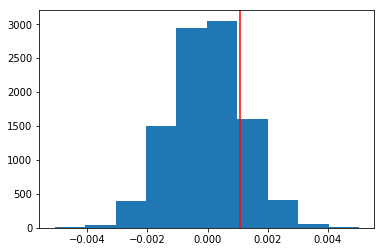

In [30]:
plt.hist(p_diffs);
plt.axvline(x=obs_diff, color='red')

What proportion of the **p_diffs** are greater than the actual difference observed in **ab_data.csv**?

In [31]:
p_val= (p_diffs > obs_diff ).mean()
p_val

0.186



In the **previous cell** we calculated p-value. Ti is the probability of getting our statistic or a more extreme value if the null is true.
Becuse the p-value is large، we have evidence that our statistic was likely to come from the null hypothesis. Therefore, we do not have evidence to reject the null.

We could also use a built-in to achieve similar results.  Though using the built-in might be easier to code, the above portions are a walkthrough of the ideas that are critical to correctly thinking about statistical significance. We fill in the below to calculate the number of conversions for each page, as well as the number of individuals who received each page.  `n_old` and `n_new` refer the the number of rows associated with the old page and new pages, respectively.

In [32]:
df2.head()

,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


In [33]:
convert_old = df2.query('group == "control"')["converted"].sum()
convert_new = df2.query('group == "treatment"')["converted"].sum()
n_old = df2.query('landing_page == "old_page"').shape[0]
n_new = df2.query('landing_page == "new_page"').shape[0]
print(convert_old, convert_new, n_old, n_new)

17489 17264 145274 145310


Now we use `stats.proportions_ztest` to compute your test statistic and p-value.  [Here](http://knowledgetack.com/python/statsmodels/proportions_ztest/) is a helpful link on using the built in.

In [34]:
z_score, p_value = sm.stats.proportions_ztest([convert_old, convert_new], [n_old, n_new], alternative='smaller')
z_score, p_value

(1.3109241984234394, 0.90505831275902449)

**Z-score** measures the number of standard deviations from the mean a data point and that helps us decide whether or not to reject the null . A z_score equals 1.310924 which is small. But the p-value equals 0.90505 which is quite large. Based on the p-value we accept the null hypothesis. That mean the converstions from the old page are
statistically better than the new.

<a id='regression'></a>
### Part III - A regression approach

`1.` In this final part, you will see that the result you achieved in the A/B test in Part II above can also be achieved by performing regression.<br><br> 

a. Since each row is either a conversion or no conversion, what type of regression should you be performing in this case?

**Now we will perform the regression logistic regression model.  We will use statsmodels Logit method.**

First, we need to create in df2 a column for the intercept, and create a dummy variable column for which page each user received.  We add an **intercept** column, as well as an **ab_page** column, which is 1 when an individual receives the **treatment** and 0 if **control**.

In [35]:
df2.head()

,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


In [36]:
df2['intercept'] = 1
df2['ab_page'] = pd.get_dummies(df['group'])['treatment']
df2.head()

,user_id,timestamp,group,landing_page,converted,intercept,ab_page
0,851104,2017-01-21 22:11:48.556739,control,old_page,0,1,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0,1,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0,1,1
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0,1,1
4,864975,2017-01-21 01:52:26.210827,control,old_page,1,1,0


In [37]:
#drop some columns 
df2 = df2.drop(['timestamp', 'group'], axis=1)
df2.head()

,user_id,landing_page,converted,intercept,ab_page
0,851104,old_page,0,1,0
1,804228,old_page,0,1,0
2,661590,new_page,0,1,1
3,853541,new_page,0,1,1
4,864975,old_page,1,1,0


We use statsmodels to instantiate regression model on the two columns we created , then we fit the model using the two columns we created. to predict whether or not an individual converts.

In [38]:
log_mod = sm.Logit(df2['converted'], df2[['intercept', 'ab_page']])
results = log_mod.fit()
results.summary()

Optimization terminated successfully.
         Current function value: 0.366118
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:              converted   No. Observations:               290584
Model:                          Logit   Df Residuals:                   290582
Method:                           MLE   Df Model:                            1
Date:                Sun, 12 May 2019   Pseudo R-squ.:               8.077e-06
Time:                        04:12:47   Log-Likelihood:            -1.0639e+05
converged:                       True   LL-Null:                   -1.0639e+05
                                        LLR p-value:                    0.1899
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     -1.9888      0.008   -246.669      0.000      -2.005      -1.973
ab_page       -0.0150      0.011     -1.311      0.190      -0.037       0.007
==============================================================================
"""

In logistic interpretation ,we need to exponentiate the coefficients. Each of these exponentiated values is the multiplicative change in the odds of conversion occurring. 



In [39]:
np.exp(-1.9888), np.exp(-0.0150)

(0.13685955841614492, 0.98511193960306265)

In [40]:
#because the values negative we use as 1/np.exp() to explain easy.
1/np.exp(-1.9888), 1/np.exp(-0.0150)

(7.3067603868728614, 1.0151130646157189)

We use the summary of model  to answer the following questions.

What is the p-value associated with **ab_page**? Why does it differ from the value you found in **Part II**?<br><br> 

The p_value is 0.190. These p-values differ from Part II because in the A/B test our null hypothesis states that the old page is better than, or equal to, the new page. The hypotheses in Part II is a one tail test. Part III is a two tail regression test.






Why it is a good idea to consider other factors to add into regression model. Are there any disadvantages to adding additional terms into regression model?

I think there many factors that effect on the converts . For example, the user is a child, a young person or a sane?. In other words, the age group affects  on converts.

Now along with testing if the conversion rate changes for different pages, also add an effect based on which country a user lives in. We will need to read in the **countries.csv** dataset and merge together  datasets on the appropriate rows.  [Here](https://pandas.pydata.org/pandas-docs/stable/generated/pandas.DataFrame.join.html) are the docs for joining tables. 

Does it appear that country had an impact on conversion?  

In [41]:
df3=pd.read_csv('countries.csv')
df3.head()

,user_id,country
0,834778,UK
1,928468,US
2,822059,UK
3,711597,UK
4,710616,UK


In [42]:
df3 = df3.set_index('user_id').join(df2.set_index('user_id'), how='inner')
df3.head()

,country,landing_page,converted,intercept,ab_page
user_id,,,,,
834778,UK,old_page,0,1,0
928468,US,new_page,0,1,1
822059,UK,new_page,1,1,1
711597,UK,old_page,0,1,0
710616,UK,new_page,0,1,1


In [43]:
#the number of missing values?
df3.isnull().sum()

country         0
landing_page    0
converted       0
intercept       0
ab_page         0
dtype: int64

In [44]:
df3['country'].unique()

array(['UK', 'US', 'CA'], dtype=object)

In [45]:
# create dummy variables for these country columns
df3[['UK', 'US', 'CA']] = pd.get_dummies(df3['country'])
df3 = df3.drop(['country', 'CA'], axis=1)
df3.head()

,landing_page,converted,intercept,ab_page,UK,US
user_id,,,,,,
834778,old_page,0,1,0,0,1
928468,new_page,0,1,1,0,0
822059,new_page,1,1,1,0,1
711597,old_page,0,1,0,0,1
710616,new_page,0,1,1,0,1


In [46]:
log_mod3 = sm.Logit(df3['converted'], df3[['intercept', 'ab_page', 'UK', 'US']])
results3 = log_mod3.fit()
results3.summary()

Optimization terminated successfully.
         Current function value: 0.366113
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:              converted   No. Observations:               290584
Model:                          Logit   Df Residuals:                   290580
Method:                           MLE   Df Model:                            3
Date:                Sun, 12 May 2019   Pseudo R-squ.:               2.323e-05
Time:                        04:12:48   Log-Likelihood:            -1.0639e+05
converged:                       True   LL-Null:                   -1.0639e+05
                                        LLR p-value:                    0.1760
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     -1.9893      0.009   -223.763      0.000      -2.007      -1.972
ab_page       -0.0149      0.011     -1.307      0.191      -0.037       0.007
UK            -0.0408      0.027     -1.516      0.130      -0.093       0.012
US             0.0099      0.013      0.743      0.457      -0.016       0.036
==============================================================================
"""

In [47]:
1/np.exp(-1.9893), 1/np.exp(-0.0149), 1/np.exp(-0.0408), 1/np.exp(0.0099)

(7.310414680563591,
 1.0150115583846535,
 1.0416437559600236,
 0.99014884368295708)

Through this model we conclude that:

**UK** is 1.04 times less likely to convert compared to CA overall conversions.

**US** is 0.99 times more likely to convert compared to CA overall conversions.

We would now like to look at an interaction between page and country to see if there significant effects on conversion. We create the necessary additional columns, and fit the new model. 

Provide the summary results, and your conclusions based on the results.

In [48]:
df3['UK_new_page'] = df3['UK']*df3['ab_page']
df3['US_new_page'] = df3['US']*df3['ab_page']
df3.head()


,landing_page,converted,intercept,ab_page,UK,US,UK_new_page,US_new_page
user_id,,,,,,,,
834778,old_page,0,1,0,0,1,0,0
928468,new_page,0,1,1,0,0,0,0
822059,new_page,1,1,1,0,1,0,1
711597,old_page,0,1,0,0,1,0,0
710616,new_page,0,1,1,0,1,0,1


In [49]:
log_mod3 = sm.Logit(df3['converted'], df3[['intercept', 'UK_new_page', 'US_new_page']])
results3 = log_mod3.fit()
results3.summary()

Optimization terminated successfully.
         Current function value: 0.366113
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:              converted   No. Observations:               290584
Model:                          Logit   Df Residuals:                   290581
Method:                           MLE   Df Model:                            2
Date:                Sun, 12 May 2019   Pseudo R-squ.:               2.364e-05
Time:                        04:12:49   Log-Likelihood:            -1.0639e+05
converged:                       True   LL-Null:                   -1.0639e+05
                                        LLR p-value:                   0.08085
===============================================================================
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
intercept      -1.9963      0.006   -322.049      0.000      -2.008      -1.984
UK_new_page    -0.0752      0.038     -1.997      0.046      -0.149      -0.001
US_new_page     0.0149      0.017      0.862      0.389      -0.019       0.049
===============================================================================
"""

In [50]:
1/np.exp(-0.0752), 1/np.exp(0.0149)

(1.0780997492739288, 0.9852104557227469)

Through this model we conclude that:

**UK** is 1.078 times less likely to convert compared to CA overall conversions that received the new page.

**US** is 0.985 times more likely to convert compared to CA overall conversions that received the new page.

That mean the UK conversions overall and for the new page is lower, and in the US overall and new page conversions is higher compared to the CA.




## Directions to Submit

> Before you submit your project, you need to create a .html or .pdf version of this notebook in the workspace here. To do that, run the code cell below. If it worked correctly, you should get a return code of 0, and you should see the generated .html file in the workspace directory (click on the orange Jupyter icon in the upper left).

> Alternatively, you can download this report as .html via the **File** > **Download as** submenu, and then manually upload it into the workspace directory by clicking on the orange Jupyter icon in the upper left, then using the Upload button.

> Once you've done this, you can submit your project by clicking on the "Submit Project" button in the lower right here. This will create and submit a zip file with this .ipynb doc and the .html or .pdf version you created. Congratulations!

In [51]:
from subprocess import call
call(['python', '-m', 'nbconvert', 'Analyze_ab_test_results_notebook.ipynb'])

0